# Week 1: numerical verification of Barfoot, chapter 2

Notes and experiments for *State Estimation for Robotics* (T. Barfoot), chapter 2: Primer on Probability Theory, Gaussian PDFs (sections 2.2.6 to 2.2.14).

Rule of the notebook: **every formula is checked against samples**. If theory and simulation disagree, there is a gap in my understanding.

Sections: (1) sampling, (2) linear transformation, (3) nonlinear transformation, (4) product of Gaussians, (5) Mahalanobis distance and chi-squared, (6) Cramér-Rao lower bound. Each section ends with written answers (also collected in `answers.md`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

def compare(name, theory, sample):
    theory, sample = np.atleast_1d(theory), np.atleast_1d(sample)
    err = np.max(np.abs(theory - sample))
    print(f'{name}:\n  theory = {np.round(theory, 4).tolist()}\n  sample = {np.round(sample, 4).tolist()}\n  max error = {err:.4f}\n')

def draw_ellipse(ax, mu, Sigma, n_sigma=1.0, **kw):
    # Ellipse of points whose Mahalanobis distance equals n_sigma
    vals, vecs = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2 * np.pi, 200)
    circle = np.stack([np.cos(t), np.sin(t)])
    pts = mu[:, None] + n_sigma * vecs @ (np.sqrt(vals)[:, None] * circle)
    ax.plot(pts[0], pts[1], **kw)

## 1. Sampling an N-dimensional Gaussian (section 2.2.13)

Goal: generate z ~ N(μ, Σ) using only N(0, 1) samples, with z = μ + V x and Σ = V Vᵀ.

mean:
  theory = [10.0, 5.0]
  sample = [9.9991, 5.0]
  max error = 0.0009

covariance:
  theory = [1.0, 0.8, 0.8, 1.0]
  sample = [1.0003, 0.8013, 0.8013, 1.0035]
  max error = 0.0035



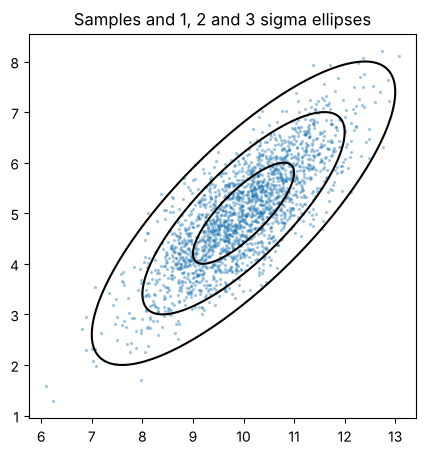

In [2]:
mu = np.array([10.0, 5.0])
Sigma = np.array([[1.0, 0.8],
                  [0.8, 1.0]])
M = 100_000  # number of samples

# 1a: factor Sigma = V V^T (Cholesky)
V = np.linalg.cholesky(Sigma)

# 1b: X has shape (2, M) with independent N(0, 1) entries (one sample per column)
X = rng.standard_normal((2, M))

# 1c: transform the samples; mu[:, None] has shape (2, 1) and is broadcast across the M columns
Z = mu[:, None] + V @ X

compare('mean', mu, Z.mean(axis=1))
compare('covariance', Sigma.ravel(), np.cov(Z).ravel())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(Z[0, :2000], Z[1, :2000], s=2, alpha=0.3)
for k in (1, 2, 3):
    draw_ellipse(ax, mu, Sigma, k, color='k')
ax.set_aspect('equal'); ax.set_title('Samples and 1, 2 and 3 sigma ellipses')
plt.show()

Experiment for Questions 1: the same sampling recipe with correlation 0.8, −0.8 and 0 (local variables, so the `Sigma` and `Z` above are untouched).

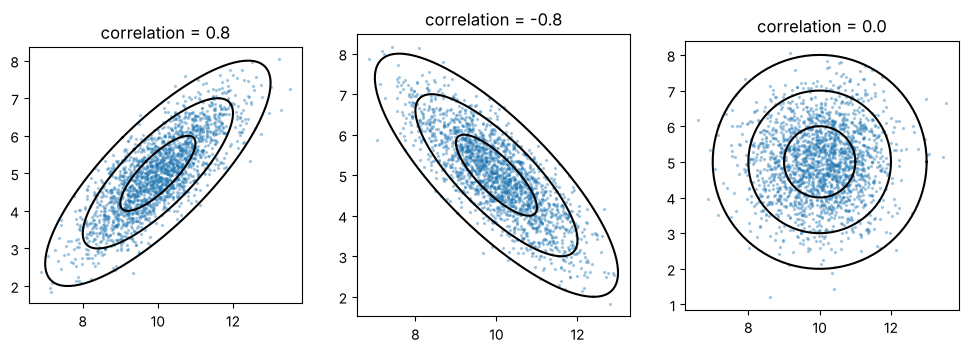

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, rho in zip(axes, [0.8, -0.8, 0.0]):
    Sigma_rho = np.array([[1.0, rho], [rho, 1.0]])
    Z_rho = mu[:, None] + np.linalg.cholesky(Sigma_rho) @ rng.standard_normal((2, M))
    ax.scatter(Z_rho[0, :2000], Z_rho[1, :2000], s=2, alpha=0.3)
    for k in (1, 2, 3):
        draw_ellipse(ax, mu, Sigma_rho, k, color='k')
    ax.set_aspect('equal'); ax.set_title(f'correlation = {rho}')
plt.show()

**Questions 1**

*Change the correlation from 0.8 to −0.8 and to 0. What happens to the cloud and why?*

With a correlation of −0.8 the cloud is flipped: it now leans the other way (negative slope). A negative correlation means that when one variable decreases the other tends to increase. With a correlation of 0 the cloud becomes a circle: since there is no relationship between the variables (and both variances are 1), the points spread equally in every direction.

*What fraction of the samples should fall inside the 1-sigma ellipse in 2D?*

39.3 %. The 1-sigma ellipse is the set of points with Mahalanobis distance d² < 1, and d² follows a χ²(2) distribution, whose CDF at 1 is 1 − e^(−1/2) ≈ 0.393. It is not the 68 % of the 1D case (see section 5).

## 2. Linear transformation y = G x (section 2.2.6)

Goal: check μ_y = G μ_x and Σ_yy = G Σ_xx Gᵀ with a 2×3 matrix G (a projection: M < N).

In [4]:
mu_x = np.array([1.0, 2.0, 3.0])
Sigma_x = np.array([[2.0, 0.3, 0.0],
                    [0.3, 1.0, 0.2],
                    [0.0, 0.2, 0.5]])
G = np.array([[1.0, 1.0, 0.0],
              [0.0, 2.0, -1.0]])

# 2a: M samples of x ~ N(mu_x, Sigma_x), reusing the recipe from section 1
V_x = np.linalg.cholesky(Sigma_x)
x = rng.standard_normal((3, M))
Xs = mu_x[:, None] + V_x @ x

# 2b: transform the samples
Ys = G @ Xs

# 2c: theoretical mean and covariance of y
mu_y_theory = G @ mu_x
Sigma_y_theory = G @ Sigma_x @ G.T

compare('mean of y', mu_y_theory, Ys.mean(axis=1))
compare('covariance of y', Sigma_y_theory.ravel(), np.cov(Ys).ravel())

mean of y:
  theory = [3.0, 1.0]
  sample = [3.0027, 1.0012]
  max error = 0.0027

covariance of y:
  theory = [3.6, 2.4, 2.4, 3.7]
  sample = [3.5911, 2.3853, 2.3853, 3.7034]
  max error = 0.0147



Experiment for Questions 2: an invertible 3×3 matrix, and the null space of the 2×3 matrix above.

In [5]:
G3 = np.array([[1.0, 1.0,  0.0],
               [0.0, 2.0, -1.0],
               [0.0, 0.0,  1.0]])
Sigma_y3 = G3 @ Sigma_x @ G3.T

print('det(G3)                       =', np.linalg.det(G3))
print('sqrt(det Sigma_yy / det Sigma_xx) =', np.sqrt(np.linalg.det(Sigma_y3) / np.linalg.det(Sigma_x)))
print('|det G3|                      =', abs(np.linalg.det(G3)))

# Null space of the 2x3 matrix G: directions that G sends to zero
null_dir = np.array([-1.0, 1.0, 2.0])
print('G @ (-1, 1, 2) =', G @ null_dir)

det(G3)                       = 2.0
sqrt(det Sigma_yy / det Sigma_xx) = 2.0
|det G3|                      = 2.0
G @ (-1, 1, 2) = [0. 0.]


**Questions 2**

*Change G to an invertible 3×3 matrix. Compute det(G) and check that the volume of the ellipse changes by |det G|.*

For the invertible matrix above, det(G) = 2 and √(det Σ_yy / det Σ_xx) = 2 as well, so both quantities agree: the volume of the ellipsoid is multiplied by |det G| = 2.

*Why can't you recover x from y when G is 2×3?*

y has only two components, so when trying to go backwards one of the components of x could take any value. G projects from 3 dimensions to 2 and collapses a whole direction, its null space, here spanned by (−1, 1, 2). All the x that differ along that direction give the same y, so y does not determine x.

## 3. Passing a Gaussian through a nonlinearity (section 2.2.7)

Goal: reproduce Figure 2.3 with y = exp(x) and see **when linearization fails**.

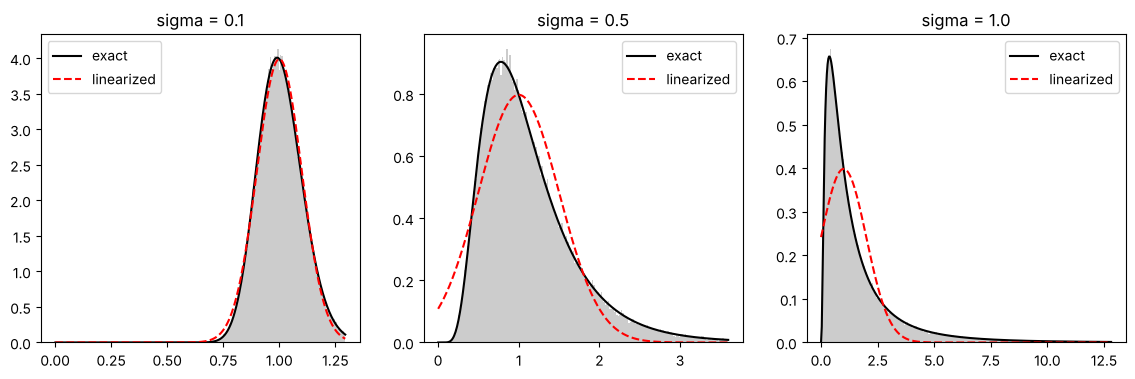

sigma = 0.1: area under exact density = 1.0000
sigma = 0.5: area under exact density = 1.0000
sigma = 1.0: area under exact density = 1.0000

sigma = 0.1:  mean true = 1.0051 vs linear = 1.0000  |  std true = 0.1009 vs linear = 0.1000
sigma = 0.5:  mean true = 1.1339 vs linear = 1.0000  |  std true = 0.6027 vs linear = 0.5000
sigma = 1.0:  mean true = 1.6462 vs linear = 1.0000  |  std true = 2.1269 vs linear = 1.0000


In [6]:
def p_y_exact(y, sigma):
    # Exact density of y = exp(x), x ~ N(0, sigma^2): change of variables, with the 1/y factor
    return (1 / (y * np.sqrt(2 * np.pi * sigma**2))) * np.exp(-0.5 * (np.log(y) / sigma) ** 2)

def linearization(mu_x, sigma):
    # Linearize g(x) = exp(x) around mu_x: mean g(mu_x), std |g'(mu_x)| * sigma
    G = np.exp(mu_x)            # Jacobian (derivative) of g at mu_x
    mu_y = np.exp(mu_x)
    sigma_y = np.sqrt(G**2 * sigma**2)
    return mu_y, sigma_y

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, sigma in zip(axes, [0.1, 0.5, 1.0]):
    x = rng.normal(0.0, sigma, M)
    y = np.exp(x)
    ys = np.linspace(1e-3, np.quantile(y, 0.995), 400)
    ax.hist(y, bins=200, density=True, color='0.8', range=(0, ys[-1]))
    ax.plot(ys, p_y_exact(ys, sigma), 'k', label='exact')
    mu_y, sigma_y = linearization(0.0, sigma)
    ax.plot(ys, stats.norm.pdf(ys, mu_y, sigma_y), 'r--', label='linearized')
    ax.set_title(f'sigma = {sigma}'); ax.legend()
plt.show()

# 3c: the area under the exact density must be 1
ys_fine = np.linspace(1e-6, 100, 200_000)
for s in [0.1, 0.5, 1.0]:
    area = np.trapezoid(p_y_exact(ys_fine, s), ys_fine)
    print(f'sigma = {s}: area under exact density = {area:.4f}')

# Sample statistics vs. the linearized ones
print()
for s in [0.1, 0.5, 1.0]:
    x = rng.normal(0.0, s, M); y = np.exp(x)
    mu_y, sigma_y = linearization(0.0, s)
    print(f'sigma = {s}:  mean true = {y.mean():.4f} vs linear = {mu_y:.4f}  |  std true = {y.std():.4f} vs linear = {sigma_y:.4f}')

**Questions 3**

*With which sigma is the linearization acceptable and with which one is it not? How does this relate to the curvature of exp(x)?*

The linearization is acceptable for sigma = 0.1. For 0.5 and 1.0 it differs noticeably from the exact density. The linearization is a first-order Taylor expansion around the expected value of x, so as sigma grows and the samples move away from that value, the approximation gets worse. Since only the first derivative is used, the curvature of exp(x) is ignored: the linearization drops terms that add spread, which is why the real spread is larger. For example, with sigma = 0.5 the real standard deviation is about 0.60 (linearized: 0.5), and with sigma = 1 the gap is much larger: about 2.16 (linearized: 1.0).

*Compare the sample mean of y with g(μ_x) = 1. Why do they not match when sigma is large?*

For sigma = 1 the sample mean of y is about 1.65, not 1 (the exact value is e^(1/2) ≈ 1.6487). The linearization only keeps g(μ_x) = 1 and drops the second-order term, which contributes ≈ ½ g″ σ² = σ²/2. Since exp is convex, the real mean lies above g(μ_x), and the difference grows with σ².

## 4. Normalized product of Gaussians (section 2.2.8)

Goal: fuse two 2D estimates with Σ⁻¹ = Σ₁⁻¹ + Σ₂⁻¹ and Σ⁻¹μ = Σ₁⁻¹μ₁ + Σ₂⁻¹μ₂, and verify the result by multiplying the densities on a grid.

fused mean:
  theory = [1.7778, 0.1111]
  sample = [1.7778, 0.1111]
  max error = 0.0000

fused covariance:
  theory = [0.4444, 0.0, 0.0, 0.4444]
  sample = [0.4444, 0.0, 0.0, 0.4444]
  max error = 0.0000

det S1 = 2.0  det S2 = 2.0  det S = 0.19753
area ratio sqrt(det S / det S1) = 0.314
entropy change = 0.5 ln(det S / det S1) = -1.158 nats


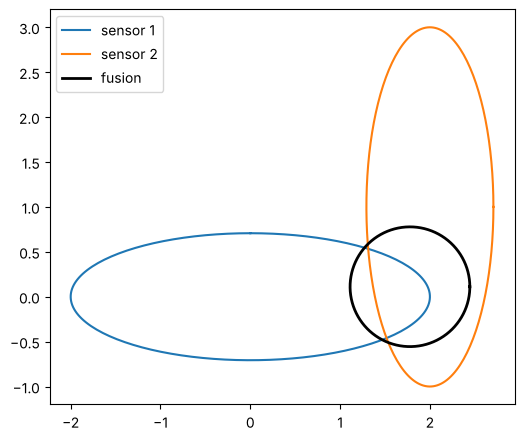

In [7]:
mu1, S1 = np.array([0.0, 0.0]), np.array([[4.0, 0.0], [0.0, 0.5]])  # sensor 1: good on the y axis
mu2, S2 = np.array([2.0, 1.0]), np.array([[0.5, 0.0], [0.0, 4.0]])  # sensor 2: good on the x axis

# 4a: fused covariance and mean (information form): informations add
Info = np.linalg.inv(S1) + np.linalg.inv(S2)
S = np.linalg.inv(Info)
mu_f = S @ (np.linalg.inv(S1) @ mu1 + np.linalg.inv(S2) @ mu2)

# Independent check: multiply the densities on a grid and normalize
g = np.linspace(-6, 8, 400)
XX, YY = np.meshgrid(g, g)
P = np.stack([XX, YY], axis=-1)
dens = stats.multivariate_normal(mu1, S1).pdf(P) * stats.multivariate_normal(mu2, S2).pdf(P)
dens /= dens.sum()
mu_grid = np.array([(dens * XX).sum(), (dens * YY).sum()])
dX, dY = XX - mu_grid[0], YY - mu_grid[1]
S_grid = np.array([[(dens * dX * dX).sum(), (dens * dX * dY).sum()],
                   [(dens * dX * dY).sum(), (dens * dY * dY).sum()]])

compare('fused mean', mu_f, mu_grid)
compare('fused covariance', S.ravel(), S_grid.ravel())

print('det S1 =', round(np.linalg.det(S1), 4), ' det S2 =', round(np.linalg.det(S2), 4), ' det S =', round(np.linalg.det(S), 5))
print('area ratio sqrt(det S / det S1) =', round(np.sqrt(np.linalg.det(S) / np.linalg.det(S1)), 3))
print('entropy change = 0.5 ln(det S / det S1) =', round(0.5 * np.log(np.linalg.det(S) / np.linalg.det(S1)), 3), 'nats')

fig, ax = plt.subplots(figsize=(6, 6))
draw_ellipse(ax, mu1, S1, color='tab:blue', label='sensor 1')
draw_ellipse(ax, mu2, S2, color='tab:orange', label='sensor 2')
draw_ellipse(ax, mu_f, S, color='k', lw=2, label='fusion')
ax.set_aspect('equal'); ax.legend(); plt.show()

**Questions 4**

*Why is the fused ellipse small along both axes, if each sensor is only good along one?*

Informations (1/variance) add axis by axis, so the fused variance is smaller than either sensor's variance along every axis. Along x: 0.25 + 2 = 2.25; along y: 2 + 0.25 = 2.25. The fused variance is 1/2.25 = 0.444 on both axes, smaller than the best single sensor (0.5): each sensor covers the axis where the other one is bad. The ratio of the ellipse areas is √(0.1975 / 2) = √0.0988 ≈ 0.314, so the fused ellipse covers only 31.4 % of the area of the S1 ellipse (it is 68.6 % smaller).

*Compare det(S) with det(S1) and det(S2). Relate it to the entropy (section 2.2.10).*

det(S1) = det(S2) = 2, while det(S) ≈ 0.1975. The entropy of a Gaussian is H = ½ ln((2πe)ᴺ det Σ), so it depends on ln det Σ: a smaller determinant means a smaller entropy. The change with respect to a single sensor is ΔH = ½ ln(0.1975 / 2) ≈ −1.16 nats.

## 5. Mahalanobis distance and chi-squared (section 2.2.9)

Goal: check that d² = (z − μ)ᵀ Σ⁻¹ (z − μ) has mean N, variance 2N and a χ²(N) distribution. Uses the samples Z from section 1.

mean of d2:
  theory = [2]
  sample = [2.0048]
  max error = 0.0048

variance of d2:
  theory = [4]
  sample = [4.0282]
  max error = 0.0282

d2 == sum of squared standard normals: True


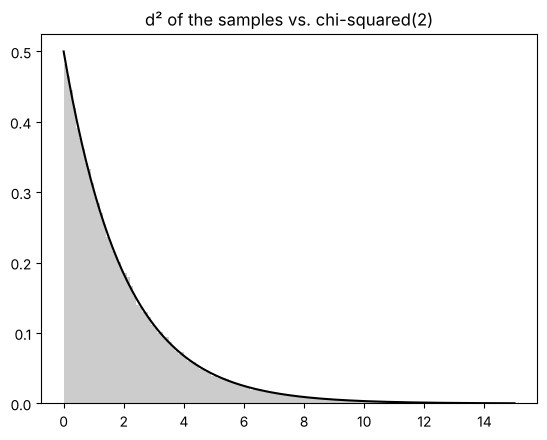

threshold: 5.991464547107979  rejected fraction: 0.05024
fraction with d2 < 1: 0.39287  theory: 0.3934693402873665

overconfident (0.5 Sigma)    mean d2 = 4.010   rejected = 0.2238
calibrated (Sigma)           mean d2 = 2.005   rejected = 0.0502
underconfident (2 Sigma)     mean d2 = 1.002   rejected = 0.0025


In [8]:
N = 2

# 5a: d2 for every column of Z, without a Python loop
A = Z - mu[:, None]                                  # (N, M): each column is one centered sample
d2 = np.sum(A * np.linalg.solve(Sigma, A), axis=0)   # (M,): a_j^T Sigma^{-1} a_j for every column j

compare('mean of d2', N, d2.mean())
compare('variance of d2', 2 * N, d2.var())

# d2 is the sum of squares of the standard normals that generated each sample
print('d2 == sum of squared standard normals:', np.allclose(d2, np.sum(X**2, axis=0)))

xs = np.linspace(0, 15, 300)
plt.hist(d2, bins=150, density=True, color='0.8', range=(0, 15))
plt.plot(xs, stats.chi2.pdf(xs, df=N), 'k')
plt.title('d² of the samples vs. chi-squared(2)'); plt.show()

# 5b: gating. 95 % threshold from the chi-squared quantile function and the fraction of samples above it
threshold = stats.chi2.ppf(0.95, df=N)
fraction = np.mean(d2 > threshold)
print('threshold:', threshold, ' rejected fraction:', fraction)

# 5c: fraction inside the 1-sigma ellipse (d2 < 1); theory: 1 - exp(-1/2)
print('fraction with d2 < 1:', np.mean(d2 < 1), ' theory:', stats.chi2.cdf(1, df=N))

# Mis-tuned filters: use c * Sigma instead of Sigma (c = 0.5 overconfident, c = 2 underconfident)
print()
for c, label in [(0.5, 'overconfident (0.5 Sigma)'), (1.0, 'calibrated (Sigma)'), (2.0, 'underconfident (2 Sigma)')]:
    d2_f = np.sum(A * np.linalg.solve(c * Sigma, A), axis=0)
    print(f'{label:28s} mean d2 = {d2_f.mean():.3f}   rejected = {np.mean(d2_f > threshold):.4f}')

**Questions 5**

*Simulate an **overconfident** filter: compute d2 with 0.5·Σ instead of Σ. What happens to the mean of d2 and to the rejected fraction?*

For the overconfident filter, d2 is multiplied by 2, so the theoretical mean is 2N = 4 and the sample mean was 4. The rejected fraction was 22 % (it should be 5 %): the filter believes it has half the uncertainty it really has, so it throws away good measurements.

*Do the same with 2·Σ (underconfident). What conclusion do you draw for tuning a filter?*

For the underconfident filter, d2 is divided by 2, so the theoretical mean is N/2 = 1 and the sample mean was 1. The rejected fraction was 0.25 %: the filter believes it has twice the uncertainty it really has, so it accepts almost everything, outliers included. To tune a filter, look for a mean of d2 close to N and, with a 95 % gate, about 5 % of rejected measurements. If the mean is above N and more than 5 % is rejected, the covariance is too small (overconfident) and must be increased; if the mean is below N and less than 5 % is rejected, the covariance is too large (underconfident) and must be reduced.

## 6. Cramér-Rao lower bound (section 2.2.14)

Goal: check that the covariance of the average of K samples is Σ/K, and compare it with the median.

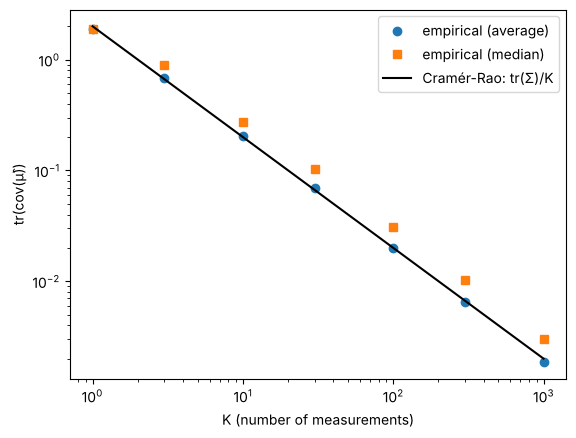

log-log slope of the average: -1.006
K     mean/CRLB   median/CRLB
1         0.950       0.950
3         1.014       1.354
10        1.017       1.379
30        1.045       1.540
100       0.990       1.546
300       0.978       1.532
1000      0.926       1.510


In [9]:
Ks = [1, 3, 10, 30, 100, 300, 1000]
n_rep = 2000
trace_mean, trace_median, trace_crlb = [], [], []

for K in Ks:
    # 6a: repeat n_rep experiments: draw K samples from N(mu, Sigma) and estimate mu from them
    mu_hats = np.empty((2, n_rep))     # estimator = average
    med_hats = np.empty((2, n_rep))    # estimator = median
    for r in range(n_rep):
        X_k = rng.standard_normal((2, K))
        Z_k = mu[:, None] + V @ X_k            # (2, K): K samples of N(mu, Sigma)
        mu_hats[:, r] = Z_k.mean(axis=1)
        med_hats[:, r] = np.median(Z_k, axis=1)
    trace_mean.append(np.trace(np.cov(mu_hats)))
    trace_median.append(np.trace(np.cov(med_hats)))
    # 6b: trace of the theoretical bound, tr(Sigma / K)
    trace_crlb.append(np.trace(Sigma) / K)

plt.loglog(Ks, trace_mean, 'o', label='empirical (average)')
plt.loglog(Ks, trace_median, 's', label='empirical (median)')
plt.loglog(Ks, trace_crlb, 'k-', label='Cramér-Rao: tr(Σ)/K')
plt.xlabel('K (number of measurements)'); plt.ylabel('tr(cov(μ̂))'); plt.legend(); plt.show()

slope = np.polyfit(np.log(Ks), np.log(trace_mean), 1)[0]
print('log-log slope of the average:', round(slope, 3))
print('K     mean/CRLB   median/CRLB')
for K, a, b, c in zip(Ks, trace_mean, trace_median, trace_crlb):
    print(f'{K:<5d} {a / c:9.3f} {b / c:11.3f}')

**Questions 6**

*What is the slope of the line on a log-log scale and why?*

The slope is −1. Since tr(cov(μ̂)) = tr(Σ)/K, taking logarithms gives log(tr) = log(tr Σ) − log K, a straight line with slope −1: multiplying K by 10 divides the variance by 10. The empirical points fall on the Cramér-Rao line.

*Replace the average by the median. Is it still on the bound? What does that say about efficient estimators?*

With the median the points stay above the bound, on a line almost parallel to the one of the average. Its variance also decreases as 1/K, but it is about π/2 ≈ 1.57 times larger than the bound (the ratio grows from 1 at K = 1 towards that value). The Cramér-Rao bound is a limit for any unbiased estimator, and only an efficient estimator (such as the average for Gaussian data) reaches it. The median is valid and unbiased but not efficient: it needs about 57 % more data to match the precision of the average.

## Closing: explain it in my own words

1. **Where G Σ Gᵀ comes from and where it appears in a Kalman filter.** G Σ Gᵀ comes from passing a Gaussian through a linear transformation. Computing cov[y] gives E[(Gx − Gμ)(Gx − Gμ)ᵀ] = G Σ Gᵀ. In a Kalman filter it appears when obtaining the covariance after passing the state or the measurements through a linear transformation (for example, the prediction and measurement models).
2. **Why linearization fails with large uncertainty.** The linearization is a Taylor series centered at the expected value, and it is only valid close to that value. As the uncertainty grows, the values move away from the expected value and the approximation breaks down.
3. **Why fusing in information form is just adding.** In the normalized product of Gaussians, the fused covariance is the inverse of the sum of the inverses of the covariances. Since the information is the inverse of the covariance, fusing several Gaussians means that the total information matrix is the sum of the information matrices of each one.
4. **How to use d² to detect a badly tuned filter.** If many samples are taken and d² is computed for each one, the values must follow a chi-squared distribution. Computing the theoretical 95 % acceptance threshold and comparing it with the percentage of samples actually rejected shows whether the filter is badly tuned: if more measurements are rejected than theory says, the filter is overconfident; if fewer, it is underconfident.
5. **What it means that the average reaches the Cramér-Rao bound.** The average is an unbiased estimator and has the smallest possible variance: no unbiased estimator can estimate the expected value with less variance than the Cramér-Rao bound allows, and the average reaches exactly that value. That is what makes it an efficient estimator.